# Noise Sensitivity — Detection Method CV (Smoke Test)

**Goal:** quick, small-scale validation that the cross-validation pipeline for Ammonyte's
detection methods works correctly end-to-end on the noise-grid synthetic data produced by
`Noise_Sensitivity_Synthetic_Data.ipynb`, before scaling this up into a broader CARC run.

**Scope of this pass (deliberately narrow — see notes inline):**
- One amplitude level: **snr3** (the middle SNR condition)
- All 3 noise colors: white, pink, red
- Two method families: **ruptures** and **KS test** (LERM deferred — its
  epsilon-search + recurrence-matrix pipeline is too slow for a fast local smoke test)
- Small parameter grids and `N_FOLDS=3` — **not** a real hyperparameter search, just
  enough to prove the CV plumbing is correct. Even so, expect **~15 minutes** total:
  KS test (`KS_test`'s nested `ks_2samp` loop) is inherently the slow part at ~5-7s per
  call on this 6001-point series, and that's multiplied across every (param, seed, fold,
  color) combination. Widen `RUPTURES_PARAM_GRID` / `KSTEST_PARAM_GRID` / `N_FOLDS` /
  `COLORS` / `LEVEL` for the real analysis (locally or in the CARC script) with that cost
  in mind.

**Cross-validation over seeds, not time:** each (color, level) condition is 20
*independent* realizations (seeds) of the same fixed dynamics, not one long series — so
folds split over seed index (`sklearn.model_selection.KFold`), not `TimeSeriesSplit`
(the pattern used for the single continuous NGRIP series in
`TippingPoints/notebooks/cv_penalty_3000.py`). Hyperparameters are calibrated by mean F1
across the training seeds in a fold, then scored once on the held-out test seeds.

**Ground truth — both directions count:** unlike the D-O event CV (which only tracks
upward/warming events, since that's what the D-O catalog lists), this synthetic model's
`state_true` transitions are a symmetric hysteresis classifier
(`climatecritters/model_critters/melcher25.py::_classify_states`) — stadial→interstadial
(warming) and interstadial→stadial (cooling) both occur and are both genuine transitions.
So every `state_true` change point is treated as ground truth, and detected transitions
are matched by time-tolerance only, ignoring detected direction.


## Section 1 — Setup

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

import ammonyte as amt
from ammonyte.utils.metrics import evaluate_detection
from sklearn.model_selection import KFold
from joblib import Parallel, delayed

warnings.filterwarnings('ignore')


In [ ]:
DATA_DIR   = "/Users/maryamniati/Documents/Syntheticdata/noise_sensitivity_data"
# OUTPUT_DIR = os.path.join(DATA_DIR, "cv_results_snr3")
# os.makedirs(OUTPUT_DIR, exist_ok=True)

LEVEL  = 'snr3'                       # single amplitude level for this smoke test
COLORS = ['white', 'pink', 'red']

N_FOLDS     = 3        # smoke-test value; use 5 (matching cv_penalty_3000.py) for the real run
TOLERANCE   = 0.5       # kyr, matching tolerance for detected vs. true transition times
RANDOM_SEED = 42
N_JOBS      = -1

# ── Parameter grids ──────────────────────────────────────────────────────────
# NOTE: deliberately tiny — just enough to prove the CV plumbing works and print sane
# numbers, not a real hyperparameter search. Still expect ~15 min total (see Section 0
# markdown): KS test dominates at ~5-7s/call, multiplied across every (param, seed,
# fold, color) combination.
#
# IMPORTANT (found by benchmarking on this 6001-point series before settling on this
# grid): 'Pelt' is slow here regardless of cost (22-46s/call), and cost='rbf' is slow
# regardless of algo (Gram-matrix computation is ~O(n^2); 24-116s/call) — both were
# ~100-1000x slower than 'Binseg' + 'l1'/'l2' (~0.1-1.8s/call, 'l1' consistently
# slower than 'l2'). That's a real property of this series length, not a smoke-test-
# only concern — the CARC script should budget for it (subsample/downsample for
# Pelt/rbf, or accept much longer runtimes, or lean on BottomUp/Window instead) rather
# than assume cv_penalty_3000.py's NGRIP timings transfer directly.
#
# For the real analysis / CARC script, widen:
#   - ruptures: more pens, more min_sizes, and reintroduce Pelt/rbf/other algos with
#     the timing caveat above in mind (see cv_penalty_3000.py PARAM_GRID)
#   - KS test: n_w back to the package default of 15, wider d_c/s_c grids
RUPTURES_PARAM_GRID = [
    {'algo': 'Binseg', 'cost': cost, 'pen': pen, 'min_size': min_size}
    for cost in ['l1', 'l2']
    for pen in [8, 16, 24, 32]
    for min_size in [15, 30]
]

KSTEST_PARAM_GRID = [
    {'w_min': 0.12, 'w_max': 2.5, 'n_w': 7, 'd_c': d_c, 'n_c': 3, 's_c': s_c, 'x_c': None}
    for d_c in [0.7, 0.8]
    for s_c in [1.5, 2.0]
]

print(f"Ruptures grid: {len(RUPTURES_PARAM_GRID)} combos")
print(f"KS test grid:  {len(KSTEST_PARAM_GRID)} combos")
print(f"N_FOLDS={N_FOLDS}, TOLERANCE={TOLERANCE} kyr, level={LEVEL}, colors={COLORS}")


Ruptures grid: 16 combos
KS test grid:  4 combos
N_FOLDS=3, TOLERANCE=0.5 kyr, level=snr3, colors=['white', 'pink', 'red']


## Section 2 — Load Noise-Grid Data & Ground Truth

In [3]:
with open(os.path.join(DATA_DIR, "noise_grid_config.json")) as f:
    grid_config = json.load(f)
print("Noise grid config:", grid_config)


def transition_times_from_states(time, states):
    """True transition times (both directions) from a state-label array.

    Mirrors the helper in Noise_Sensitivity_Synthetic_Data.ipynb: any change in the
    stadial(1)/interstadial(0) classification counts as a ground-truth transition,
    regardless of direction (see Section 1 markdown for why both directions count here).
    """
    change_idx = np.where(np.diff(states) != 0)[0] + 1
    return time[change_idx]


Noise grid config: {'sigma': 0.5, 'gamma': 1.5, 'alpha': -0.5, 't_span': [0, 120], 'dt': 0.02, 'y0': [1.0, 0.0], 'noise_colors': {'white': 0.0, 'pink': 1.0, 'red': 2.0}, 'noise_levels': {'snr4': 0.088, 'snr3': 0.1173, 'snr2': 0.176}, 'n_seeds': 20}


In [4]:
condition_data = {}

for color in COLORS:
    path = os.path.join(DATA_DIR, f"noise_{color}_{LEVEL}.npz")
    d = np.load(path)

    time = d['time']
    db_noisy = d['db_noisy']        # (n_seeds, n_time)
    state_true = d['state_true']    # (n_seeds, n_time)
    n_seeds = db_noisy.shape[0]

    gt_times = [transition_times_from_states(time, state_true[s]) for s in range(n_seeds)]

    n_up = sum(np.sum(np.diff(state_true[s]) < 0) for s in range(n_seeds))    # stadial->interstadial (warming)
    n_down = sum(np.sum(np.diff(state_true[s]) > 0) for s in range(n_seeds))  # interstadial->stadial (cooling)

    condition_data[color] = dict(time=time, db_noisy=db_noisy, gt_times=gt_times, n_seeds=n_seeds)
    print(f"{color:5s}: {n_seeds} seeds, "
          f"mean {np.mean([len(g) for g in gt_times]):.1f} true transitions/seed "
          f"({n_up} warming, {n_down} cooling across all seeds — both directions kept as ground truth)")


white: 20 seeds, mean 44.9 true transitions/seed (452 warming, 445 cooling across all seeds — both directions kept as ground truth)
pink : 20 seeds, mean 44.9 true transitions/seed (452 warming, 445 cooling across all seeds — both directions kept as ground truth)
red  : 20 seeds, mean 44.9 true transitions/seed (452 warming, 445 cooling across all seeds — both directions kept as ground truth)


## Section 3 — Method Wrappers

Each wrapper takes a raw `(time, value)` pair plus method-specific hyperparameters and returns a cleaned array of detected transition times (the `NaN` "no transitions found" sentinel used by both `ruptures_transition` and `KS_test` is dropped).

In [5]:
def _clean_times(times):
    times = np.asarray(times, dtype=float)
    return times[~np.isnan(times)]


def detect_ruptures(time, value, algo, cost, pen, min_size):
    series = amt.Series(time=time, value=value, label='cv', verbose=False)
    transitions = series.ruptures(algo=algo, cost=cost, pen=pen, min_size=min_size)
    return _clean_times(transitions.jump_times)


def detect_kstest(time, value, w_min, w_max, n_w, d_c, n_c, s_c, x_c):
    series = amt.Series(time=time, value=value, label='cv', verbose=False)
    transitions = series.kstest(w_min=w_min, w_max=w_max, n_w=n_w, d_c=d_c, n_c=n_c, s_c=s_c, x_c=x_c)
    return _clean_times(transitions.jump_times)


## Section 4 — CV Framework (Method-Agnostic)

Folds split over **seed index** (independent realizations), not time. `calibrate()`
picks the parameter combo with the best mean F1 across training seeds; `run_cv()` wraps
that in a K-fold loop and scores the calibrated params on each fold's held-out test
seeds — the same calibrate-then-test-fold shape as `cv_penalty_3000.py`, adapted to
repeated-realization data.

Both `calibrate()` and the test-fold scoring flatten work into one `(param, seed)` job
list for `joblib.Parallel` rather than parallelizing over the parameter grid alone —
with grids this small (12-16 combos), parallelizing only over combos leaves most cores
idle; flattening over every (param, seed) pair keeps all cores busy regardless of grid
size.


In [6]:
def kfold_splits(n_seeds, n_folds=N_FOLDS, seed=RANDOM_SEED):
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=seed)
    return list(kf.split(np.arange(n_seeds)))


def _score_one(detect_fn, params, time, value, gt, tolerance):
    try:
        detected = detect_fn(time, value, **params)
    except Exception:
        return 0.0, 0.0, 0.0
    m = evaluate_detection(detected=detected, ground_truth=gt, tolerance=tolerance)
    return m.precision, m.recall, m.f1_score


def calibrate(detect_fn, param_grid, time, db_noisy, gt_times, train_idx,
              tolerance=TOLERANCE, n_jobs=N_JOBS):
    jobs = [(pi, s) for pi in range(len(param_grid)) for s in train_idx]
    results = Parallel(n_jobs=n_jobs)(
        delayed(_score_one)(detect_fn, param_grid[pi], time, db_noisy[s], gt_times[s], tolerance)
        for pi, s in jobs
    )
    f1_by_param = [[] for _ in param_grid]
    for (pi, _), (_, _, f1) in zip(jobs, results):
        f1_by_param[pi].append(f1)
    mean_f1 = [float(np.mean(v)) for v in f1_by_param]
    best_i = int(np.argmax(mean_f1))
    return param_grid[best_i], mean_f1[best_i]


def score_on_seeds(detect_fn, params, time, db_noisy, gt_times, seed_idx,
                    tolerance=TOLERANCE, n_jobs=N_JOBS):
    results = Parallel(n_jobs=n_jobs)(
        delayed(_score_one)(detect_fn, params, time, db_noisy[s], gt_times[s], tolerance)
        for s in seed_idx
    )
    precisions, recalls, f1s = zip(*results)
    return float(np.mean(precisions)), float(np.mean(recalls)), float(np.mean(f1s))


def run_cv(method_name, detect_fn, param_grid, time, db_noisy, gt_times, n_folds=N_FOLDS):
    n_seeds = db_noisy.shape[0]
    fold_results = []

    for fold_idx, (train_idx, test_idx) in enumerate(kfold_splits(n_seeds, n_folds)):
        best_params, train_f1 = calibrate(detect_fn, param_grid, time, db_noisy, gt_times, train_idx)
        test_precision, test_recall, test_f1 = score_on_seeds(
            detect_fn, best_params, time, db_noisy, gt_times, test_idx
        )

        fold_results.append(dict(
            method=method_name, fold=fold_idx,
            train_f1=train_f1,
            test_precision=test_precision,
            test_recall=test_recall,
            test_f1=test_f1,
            best_params=best_params,
        ))
        print(f"  [{method_name}] fold {fold_idx}: "
              f"train_f1={train_f1:.3f}  test_f1={test_f1:.3f}  params={best_params}")

    return fold_results


## Section 5 — Run the Smoke Test

Loops over colors x methods, checkpointing to CSV after each (method, color) pair so a
partial run isn't lost. **Takes ~15 minutes** with the grids above (validated end-to-end
before this notebook was handed off) — if you need to stop partway,
`cv_results_snr3/checkpoint.csv` will have every (method, color, fold) completed so far.


In [7]:
all_fold_results = []
# checkpoint_path = os.path.join(OUTPUT_DIR, 'checkpoint.csv')


# def _checkpoint():
#     pd.DataFrame(all_fold_results).to_csv(checkpoint_path, index=False)


for color in COLORS:
    d = condition_data[color]
    print(f"\n=== {color} ({LEVEL}) ===")

    print(" ruptures:")
    rup_results = run_cv('ruptures', detect_ruptures, RUPTURES_PARAM_GRID,
                          d['time'], d['db_noisy'], d['gt_times'])
    for r in rup_results:
        r['color'] = color
    all_fold_results.extend(rup_results)
    # _checkpoint()

    print(" ks test:")
    ks_results = run_cv('kstest', detect_kstest, KSTEST_PARAM_GRID,
                         d['time'], d['db_noisy'], d['gt_times'])
    for r in ks_results:
        r['color'] = color
    all_fold_results.extend(ks_results)
    # _checkpoint()

results_df = pd.DataFrame(all_fold_results)
results_df
print(f"\nCollected {len(results_df)} fold results (in-memory only)")
# results_df.to_csv(os.path.join(OUTPUT_DIR, 'cv_results.csv'), index=False)
# print(f"\nSaved {len(results_df)} fold results to {OUTPUT_DIR}/cv_results.csv")



=== white (snr3) ===
 ruptures:
  [ruptures] fold 0: train_f1=0.510  test_f1=0.472  params={'algo': 'Binseg', 'cost': 'l1', 'pen': 8, 'min_size': 15}
  [ruptures] fold 1: train_f1=0.487  test_f1=0.515  params={'algo': 'Binseg', 'cost': 'l1', 'pen': 8, 'min_size': 15}
  [ruptures] fold 2: train_f1=0.494  test_f1=0.504  params={'algo': 'Binseg', 'cost': 'l1', 'pen': 8, 'min_size': 15}
 ks test:
  [kstest] fold 0: train_f1=0.497  test_f1=0.516  params={'w_min': 0.12, 'w_max': 2.5, 'n_w': 7, 'd_c': 0.8, 'n_c': 3, 's_c': 2.0, 'x_c': None}
  [kstest] fold 1: train_f1=0.510  test_f1=0.491  params={'w_min': 0.12, 'w_max': 2.5, 'n_w': 7, 'd_c': 0.8, 'n_c': 3, 's_c': 2.0, 'x_c': None}
  [kstest] fold 2: train_f1=0.504  test_f1=0.503  params={'w_min': 0.12, 'w_max': 2.5, 'n_w': 7, 'd_c': 0.8, 'n_c': 3, 's_c': 2.0, 'x_c': None}

=== pink (snr3) ===
 ruptures:
  [ruptures] fold 0: train_f1=0.553  test_f1=0.558  params={'algo': 'Binseg', 'cost': 'l1', 'pen': 8, 'min_size': 15}
  [ruptures] fold 1: 

## Section 6 — Results Summary

In [8]:
summary = (results_df
           .groupby(['method', 'color'])[['test_f1', 'test_precision', 'test_recall']]
           .agg(['mean', 'std'])
           .round(3))
summary


test_f1        test_precision        test_recall       
                  mean    std           mean    std        mean    std
method   color                                                        
kstest   pink    0.299  0.007          0.177  0.005       0.989  0.007
         red     0.281  0.004          0.164  0.003       0.997  0.001
         white   0.504  0.012          0.347  0.009       0.930  0.025
ruptures pink    0.554  0.004          0.791  0.021       0.439  0.007
         red     0.583  0.040          0.809  0.022       0.463  0.050
         white   0.497  0.022          0.844  0.050       0.365  0.023

In [9]:
for method in ['ruptures', 'kstest']:
    print(f"\n{method} — best params per (color, fold):")
    sub = results_df[results_df['method'] == method][['color', 'fold', 'best_params']]
    print(sub.to_string(index=False))



ruptures — best params per (color, fold):
color  fold                                                best_params
white     0 {'algo': 'Binseg', 'cost': 'l1', 'pen': 8, 'min_size': 15}
white     1 {'algo': 'Binseg', 'cost': 'l1', 'pen': 8, 'min_size': 15}
white     2 {'algo': 'Binseg', 'cost': 'l1', 'pen': 8, 'min_size': 15}
 pink     0 {'algo': 'Binseg', 'cost': 'l1', 'pen': 8, 'min_size': 15}
 pink     1 {'algo': 'Binseg', 'cost': 'l1', 'pen': 8, 'min_size': 30}
 pink     2 {'algo': 'Binseg', 'cost': 'l1', 'pen': 8, 'min_size': 30}
  red     0 {'algo': 'Binseg', 'cost': 'l1', 'pen': 8, 'min_size': 15}
  red     1 {'algo': 'Binseg', 'cost': 'l1', 'pen': 8, 'min_size': 15}
  red     2 {'algo': 'Binseg', 'cost': 'l1', 'pen': 8, 'min_size': 15}

kstest — best params per (color, fold):
color  fold                                                                            best_params
white     0 {'w_min': 0.12, 'w_max': 2.5, 'n_w': 7, 'd_c': 0.8, 'n_c': 3, 's_c': 2.0, 'x_c': None}
white   

## Section 7 — Noise-Sensitivity Plot

Test F1 (from CV-optimized parameters) by noise color, faceted by method — a first look at whether optimized detection quality varies by noise color at fixed amplitude (snr3).

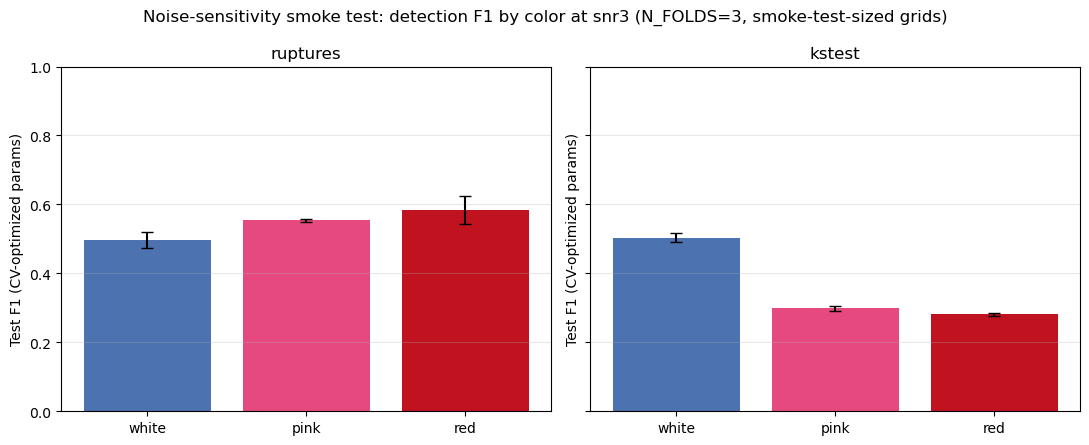

In [10]:
color_order = ['white', 'pink', 'red']
plot_colors = {'white': '#4c72b0', 'pink': '#e64980', 'red': '#c1121f'}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

for ax, method in zip(axes, ['ruptures', 'kstest']):
    sub = results_df[results_df['method'] == method]
    means = sub.groupby('color')['test_f1'].mean().reindex(color_order)
    stds = sub.groupby('color')['test_f1'].std().reindex(color_order)
    ax.bar(color_order, means, yerr=stds, color=[plot_colors[c] for c in color_order], capsize=4)
    ax.set_title(method)
    ax.set_ylabel('Test F1 (CV-optimized params)')
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle(f'Noise-sensitivity smoke test: detection F1 by color at {LEVEL} '
             f'(N_FOLDS={N_FOLDS}, smoke-test-sized grids)')
plt.tight_layout()
plt.show()
